# Speed, batches and gradients

Everything in `jaxley_ephys` is written in JAX: it is compiled, can be batched
with `jax.vmap` and differentiated with `jax.grad`. This example uses a batch of
simulated sweeps from a minimal Hodgkin-Huxley model of this repository's tests
(any simulator works the same way, e.g. [Jaxley](https://github.com/jaxleyverse/jaxley)).

In [1]:
import sys
import time
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

jax.config.update("jax_enable_x64", True)

REPO = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
sys.path.insert(0, str(REPO))

from jaxley_ephys import detect_spikes, spike_features, sweep_features  # noqa: E402
from tests.utils.simulate_testdata import simulate_sweep, simulate_sweepset  # noqa: E402

# 128 sweeps of 0.1 s at 40 kHz with increasing current steps from 20 to 80 ms
t, v, i = simulate_sweepset(
    num_sweeps=128,
    dt=2.5e-5,
    t_max=0.1,
    stim_delay=0.02,
    stim_dur=0.06,
    i_range=(-0.3, 1.0),
)
print(t.shape)

(128, 4000)


## Compiled once per length

The functions are compiled on their first call for each trace length (a few
seconds) and fast afterwards. JAX can keep the compiled code across sessions:
`jax.config.update("jax_compilation_cache_dir", "/path/to/cache")`.

In [2]:
def analyse(t, v, i):
    return sweep_features(detect_spikes(t, v, i, 0.02, 0.08))


for k in range(3):
    tic = time.perf_counter()
    jax.block_until_ready(analyse(t[k], v[k], i[k]))
    print(f"call {k}: {1e3 * (time.perf_counter() - tic):.0f} ms")

call 0: 3853 ms
call 1: 6 ms
call 2: 6 ms


## Batches

`jax.vmap` analyses the whole batch at once. Inside `vmap` and `jit`, no error can
be raised if a sweep has more putative spikes than `max_spikes`; check
`overflow` instead.

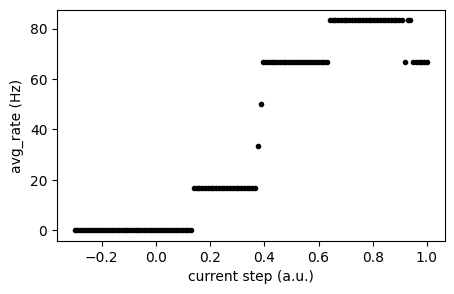

In [3]:
@jax.jit
@jax.vmap
def batch(t, v, i):
    sp = detect_spikes(t, v, i, 0.02, 0.08)
    return sp.overflow, sweep_features(sp)


overflow, features = batch(t, v, i)
assert not overflow.any()
plt.figure(figsize=(5, 3))
plt.plot(i[:, 1000], features["avg_rate"], "k.")
plt.xlabel("current step (a.u.)")
plt.ylabel("avg_rate (Hz)")
plt.show()

Sweeps of different lengths can be batched, too: pad the shorter ones with NaN
times. Samples with NaN times are not part of the sweep.

In [4]:
t_padded = np.array(t[-2:])
t_padded[1, 3400:] = np.nan  # the second sweep ends at 85 ms
padded = batch(jnp.asarray(t_padded), v[-2:], i[-2:])[1]
alone = analyse(t[-1, :3400], v[-1, :3400], i[-1, :3400])
print(
    f"mean ISI: {float(padded['mean_isi'][1]):.4f} ms padded, "
    f"{float(alone['mean_isi']):.4f} ms alone"
)

mean ISI: 12.7250 ms padded, 12.7250 ms alone


## Gradients

Features that depend smoothly on the voltage can be differentiated, e.g. the peak
voltage of the first spike with respect to the stimulus amplitude of the simulation.
Spike times and counts change in steps, so their gradients are zero.

In [5]:
def first_peak(stim_amp):
    t, v, i = simulate_sweep(
        dt=2.5e-5, t_max=0.1, stim_amp=stim_amp, stim_delay=0.02, stim_dur=0.06
    )
    sp = detect_spikes(t, v, i, 0.02, 0.08, max_spikes=16)
    return spike_features(sp)["peak_v"][0]


value, grad = jax.value_and_grad(first_peak)(0.5)
print(f"peak voltage {float(value):.2f} mV, d(peak)/d(stim_amp) = {float(grad):.2f}")

peak voltage 40.58 mV, d(peak)/d(stim_amp) = -30.23


## float32

Without `jax_enable_x64`, JAX computes in float32, which is faster on GPUs and
uses half the memory. The results then deviate slightly from Allen's (features by
about 1e-4; see `allen_ephys/ALLEN_EPHYS_FIXES.md`).